# Exercício - Mini Projeto de Análise de Dados

Vamos fazer um exercício completo de pandas para um miniprojeto de análise de dados.

Esse exercício vai obrigar a gente a usar boa parte dos conhecimento de pandas e até de outros módulos que já aprendemos ao longo do curso.

### O que temos?

Temos os dados de 2019 de uma empresa de prestação de serviços. 

- CadastroFuncionarios
- CadastroClientes
- BaseServiçosPrestados

Obs1: Para ler arquivos csv, temos o read_csv<br>
Obs2: Para ler arquivos xlsx (arquivos em excel normais, que não são padrão csv), temos o read_excel

### O que queremos saber/fazer?

1. Valor Total da Folha Salarial -> Qual foi o gasto total com salários de funcionários pela empresa? <br>
    Sugestão: calcule o salário total de cada funcionário, salário + benefícios + impostos, depois some todos os salários
    
    
2. Qual foi o faturamento da empresa?<br>
    Sugestão: calcule o faturamento total de cada serviço e depois some o faturamento de todos
    
    
3. Qual o % de funcionários que já fechou algum contrato?<br>
    Sugestão: na base de serviços temos o funcionário que fechou cada serviço. Mas nem todos os funcionários que a empresa tem já fecharam algum serviço.<br>
    . Na base de funcionários temos uma lista com todos os funcionários<br>
    . Queremos calcular Qtde_Funcionarios_Fecharam_Serviço / Qtde_Funcionários_Totais<br>
    . Para calcular a qtde de funcionários que fecharam algum serviço, use a base de serviços e conte quantos funcionários tem ali. Mas lembre-se, cada funcionário só pode ser contado uma única vez.<br><br>
    Dica: se você aplicar o método .unique() em uma variável que é apenas 1 coluna de um dataframe, ele vai excluir todos os valores duplicados daquela coluna.<br>
    Ex: unicos_colunaA = dataframe['colunaA'].unique() te dá como resposta uma lista com todos os itens da colunaA aparecendo uma única vez. Todos os valores repetidos da colunaA são excluidos da variável unicos_colunaA 
    
    
4. Calcule o total de contratos que cada área da empresa já fechou


5. Calcule o total de funcionários por área


6. Qual o ticket médio mensal (faturamento médio mensal) dos contratos?<br>
    Dica: .mean() calcula a média -> exemplo: media_colunaA = dataframe['colunaA'].mean()

Obs: Lembrando as opções mais usuais de encoding:<br>
encoding='latin1', encoding='ISO-8859-1', encoding='utf-8' ou então encoding='cp1252'

Observação Importante: Se o seu código der um erro na hora de importar os arquivos:<br>
- CadastroClientes.csv
- CadastroFuncionarios.csv

Use separador ";" (ponto e vírgula) para resolver

### Impoeteção de Módulos e Aquivos

In [2]:
import pandas as pd

# Base de dados
funcionarios_df = pd.read_csv('CadastroFuncionarios.csv', sep=';', decimal=',') # para nao da erra usar Decimal=',' 
clientes_df = pd.read_csv('CadastroClientes.csv', sep=';', decimal=',') # para nao da erra usar Decimal=','
servico_df = pd.read_excel('BaseServiçosPrestados.xlsx') # Aqui não precisa do sep=';', decimal=','


In [3]:
# ver o que tem na colulas
funcionarios_df.info()
clientes_df.info()
servico_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID Funcionário  114 non-null    int64  
 1   Estado Civil    114 non-null    str    
 2   Nome Completo   114 non-null    str    
 3   Salario Base    114 non-null    int64  
 4   Impostos        114 non-null    float64
 5   Beneficios      114 non-null    float64
 6   VT              114 non-null    int64  
 7   VR              114 non-null    float64
 8   Cargo           114 non-null    str    
 9   Area            114 non-null    str    
dtypes: float64(3), int64(3), str(4)
memory usage: 9.0 KB
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   ID Cliente             320 non-null    int64
 1   Cliente                320 non-null    str  
 2   Valor Cont

In [4]:
# ver as tabelas

display(funcionarios_df)
display(clientes_df)
display(servico_df)

,ID Funcionário,Estado Civil,Nome Completo,Salario Base,Impostos,Beneficios,VT,VR,Cargo,Area
0,1,C,Gabriel Mesquita,21910,10955.0,4382.0,242,719.04,Diretor,Operações
1,2,C,João Haddad,5404,2702.0,1080.8,154,574.56,Estagiário,Logística
2,3,C,Amanda Marques Ribeiro,16066,8033.0,3213.2,154,729.12,Estagiário,Administrativo
3,4,C,Guilherme Nunez,21305,10652.5,4261.0,220,524.16,Analista,Administrativo
4,5,C,Adelino Gomes,5098,2549.0,1019.6,176,725.76,Analista,Administrativo
...,...,...,...,...,...,...,...,...,...,...
109,143,C,Renan Scharnhorst Ott,10793,5396.5,2158.6,242,514.08,Analista,Logística
110,144,S,Lucas Brum Pereira,4048,2024.0,809.6,198,796.32,Estagiário,Comercial
111,148,S,Caio Stellet,24596,12298.0,4919.2,242,561.12,Analista,Administrativo
112,149,C,Fernanda Rocha,5078,2539.0,1015.6,308,665.28,Estagiário,Comercial


,ID Cliente,Cliente,Valor Contrato Mensal
0,1,Teixeira Gonçalves,540
1,2,Souza Santos,1260
2,3,Emídio Alves,3195
3,4,Santos Costa,2520
4,5,Do Monteiro,3510
...,...,...,...
315,316,Manoel Costa,3690
316,317,Gomes Machado,2385
317,318,Alkindar Cardozo,3510
318,319,Pereira Fazenda,4185


,Codigo do Servico,ID Funcionário,ID Cliente,Tempo Total de Contrato (Meses)
0,OS0001,67,1,14
1,OS0002,17,2,12
2,OS0003,116,4,14
3,OS0004,37,5,8
4,OS0005,130,6,8
...,...,...,...,...
232,OS0233,111,315,4
233,OS0234,124,316,8
234,OS0235,72,317,6
235,OS0236,90,319,14


In [5]:
# remover as colunas Estado Civil e Cargo da tabela de Funcionarios
funcionarios_df = funcionarios_df.drop(['Estado Civil','Cargo'], axis=1) # tem que expecificar (axis=1) para coluna
display(funcionarios_df)


,ID Funcionário,Nome Completo,Salario Base,Impostos,Beneficios,VT,VR,Area
0,1,Gabriel Mesquita,21910,10955.0,4382.0,242,719.04,Operações
1,2,João Haddad,5404,2702.0,1080.8,154,574.56,Logística
2,3,Amanda Marques Ribeiro,16066,8033.0,3213.2,154,729.12,Administrativo
3,4,Guilherme Nunez,21305,10652.5,4261.0,220,524.16,Administrativo
4,5,Adelino Gomes,5098,2549.0,1019.6,176,725.76,Administrativo
...,...,...,...,...,...,...,...,...
109,143,Renan Scharnhorst Ott,10793,5396.5,2158.6,242,514.08,Logística
110,144,Lucas Brum Pereira,4048,2024.0,809.6,198,796.32,Comercial
111,148,Caio Stellet,24596,12298.0,4919.2,242,561.12,Administrativo
112,149,Fernanda Rocha,5078,2539.0,1015.6,308,665.28,Comercial


### Folha Salarial

In [15]:
# Adicionado um colula Salario Total
funcionarios_df['Salario Total'] = funcionarios_df['Salario Base'] + funcionarios_df['Impostos'] + funcionarios_df['Beneficios'] + funcionarios_df['VT'] + funcionarios_df['VR']

# Mostra total
print("Total de Folha Salarial é R$ {:,}" .format(funcionarios_df['Salario Total'].sum()))

Total de Folha Salarial é R$ 2,717,493.22


### Fatumento da Empresa

In [ ]:
# Unir duas tabela a servico_df e a clientes_df
faturamentos_df = servico_df[['ID Cliente','Tempo Total de Contrato (Meses)']].merge(clientes_df[['ID Cliente',"Valor Contrato Mensal"]], on="ID Cliente")

display(faturamentos_df)

,ID Cliente,Tempo Total de Contrato (Meses),Valor Contrato Mensal
0,1,14,540
1,2,12,1260
2,4,14,2520
3,5,8,3510
4,6,8,2340
...,...,...,...
232,315,4,1575
233,316,8,3690
234,317,6,2385
235,319,14,4185


In [ ]:
# Soma de Faturmento Total
faturamentos_df['Faturamento Total'] = faturamentos_df['Tempo Total de Contrato (Meses)'] * faturamentos_df['Valor Contrato Mensal']

print('Faturamento Total: R$ {:,}'.format(sum(faturamentos_df["Faturamento Total"])))

Faturamento Total: R$ 5,519,160


### Funcionarios Fecharam Contrato

In [27]:
# Quantidade de Funcionarios Que fecheram contrato

q_funcionarios_fecharam_cobtrato = len(servico_df["ID Funcionário"].unique())
q_funcionarios_toatal = len(funcionarios_df["ID Funcionário"])

print('Peecentual Funcionários que Fecharam contrato: {:.2%} '.format(q_funcionarios_fecharam_cobtrato/q_funcionarios_toatal))

Peecentual Funcionários que Fecharam contrato: 86.84% 


### Quantidade de Contratos por Área

In [ ]:
# fazer merge para pegar as infromaçao Funcionario e area
contratos_area_df = servico_df[["ID Funcionário"]].merge(funcionarios_df[["ID Funcionário","Area"]], on='ID Funcionário')

contratos_area_qtde = contratos_area_df['Area'].value_counts()

display(contratos_area_qtde)


Area
Administrativo    63
Operações         48
Comercial         44
Financeiro        42
Logística         40
Name: count, dtype: int64

Area
Administrativo    63
Operações         48
Comercial         44
Financeiro        42
Logística         40
Name: count, dtype: int64


### Funcionarios por Area

Area
Administrativo    26
Comercial         26
Operações         23
Logística         21
Financeiro        18
Name: count, dtype: int64

<Axes: xlabel='Area'>

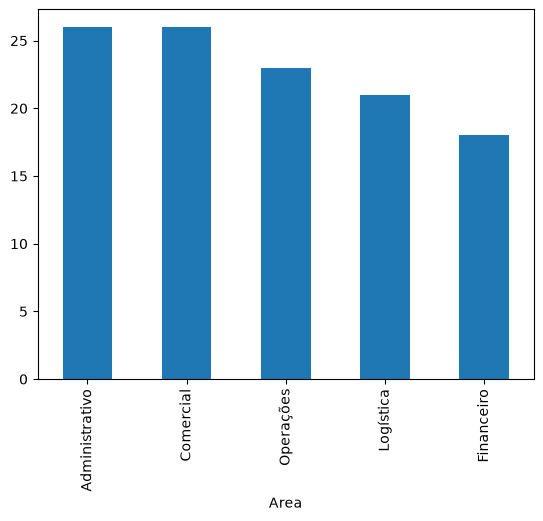

In [ ]:
# Grafico de Barras
funcionarios_area = funcionarios_df["Area"].value_counts()
display(funcionarios_area)

funcionarios_area.plot(kind='bar')

### Ticket Médio Mensal

In [44]:
# usar o .mean para fazer o calculo
ticket_medio = clientes_df['Valor Contrato Mensal'].mean()

print('Ticket Médio Mensal: R$ {:,.2f}'.format(ticket_medio))

Ticket Médio Mensal: R$ 2,502.56
